# 02 - Model evaluation

Run `python ml/src/train.py` first. It trains and compares the models, then saves the model, `model_card.json`, `cv_results.csv` and the plots.
This notebook only **reads** those results and checks them. It does not retrain anything.

In [1]:
import sys, json
from pathlib import Path

# Same path trick as 01_eda.ipynb: make ml/src importable
project_root = Path.cwd().parent.parent
sys.path.append(str(project_root / "ml" / "src"))

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display

import features                      # needed so the saved model can be unpickled
from train import get_split          # same split as training (fixed seed)

MODELS = project_root / "ml" / "models"
REPORTS = project_root / "ml" / "reports"

model = joblib.load(MODELS / "model.joblib")
card = json.loads((MODELS / "model_card.json").read_text())

print("Selected model :", card["model"], "on", card["feature_set"], "features")
print("Best params    :", card["best_params"])
print("Features used  :", card["features_used_by_model"])
print("Threshold      :", round(card["threshold"], 3), f"(target recall {card['target_recall']:.0%} on train out-of-fold)")

Selected model : logreg on baseline features
Best params    : {'model__C': 0.01, 'select': 'RFE(75%)'}
Features used  : ['Pregnancies', 'Glucose', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Threshold      : 0.284 (target recall 80% on train out-of-fold)


## 1. Cross-validated model comparison (train data only)

,feature_set,model,cv_roc_auc,cv_roc_auc_std,cv_pr_auc,cv_recall,cv_precision,cv_f1
0,engineered,svm,0.851,0.030,0.756,0.731,0.652,0.682
1,baseline,svm,0.850,0.024,0.754,0.703,0.653,0.672
2,engineered,logreg,0.847,0.028,0.744,0.748,0.656,0.693
3,baseline,logreg,0.846,0.028,0.742,0.720,0.657,0.681
4,engineered,mlp,0.846,0.037,0.744,0.640,0.709,0.668
5,baseline,mlp,0.843,0.034,0.734,0.615,0.700,0.651


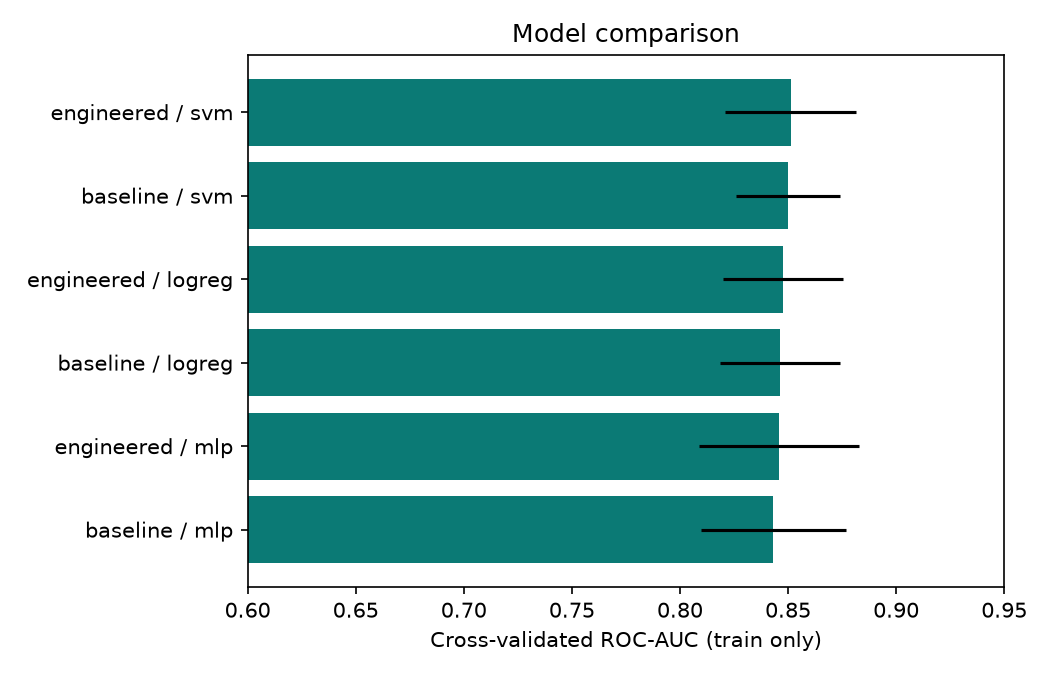

In [2]:
cv = pd.read_csv(REPORTS / "cv_results.csv")
cols = ["feature_set", "model", "cv_roc_auc", "cv_roc_auc_std", "cv_pr_auc", "cv_recall", "cv_precision", "cv_f1"]
display(cv[cols].round(3))
display(Image(REPORTS / "model_comparison.png"))

**How to read this:** ROC-AUC differences of about 0.01 are smaller than the fold-to-fold spread (the `std` column), so the models are effectively tied.
`train.py` therefore prefers the simplest model within 0.005 AUC of the best. Compare the `baseline` and `engineered` rows for the same model: if they match, the engineered features are not adding signal.

## 2. Held-out test set (evaluated once)

In [3]:
_, X_test, _, y_test = get_split()
proba = model.predict_proba(X_test)[:, 1]
thr = card["threshold"]

t = card["test"]
print(f"ROC-AUC {t['roc_auc']:.3f}  (95% bootstrap CI {t['roc_auc_95ci'][0]:.3f} - {t['roc_auc_95ci'][1]:.3f})")
print(f"PR-AUC  {t['pr_auc']:.3f}   Brier score {t['brier']:.3f}")
print("Majority-class accuracy (predict 'no diabetes' for everyone):", round(t["majority_class_accuracy"], 3))

pd.DataFrame({"at chosen threshold": t["at_chosen_threshold"], "at 0.5": t["at_0.5"]}).round(3)

ROC-AUC 0.806  (95% bootstrap CI 0.736 - 0.867)
PR-AUC  0.652   Brier score 0.179
Majority-class accuracy (predict 'no diabetes' for everyone): 0.649


,at chosen threshold,at 0.5
threshold,0.284,0.500
accuracy,0.708,0.734
precision,0.560,0.633
recall,0.778,0.574
specificity,0.670,0.820
f1,0.651,0.602
tn,67.000,82.000
fp,33.000,18.000
fn,12.000,23.000
tp,42.000,31.000


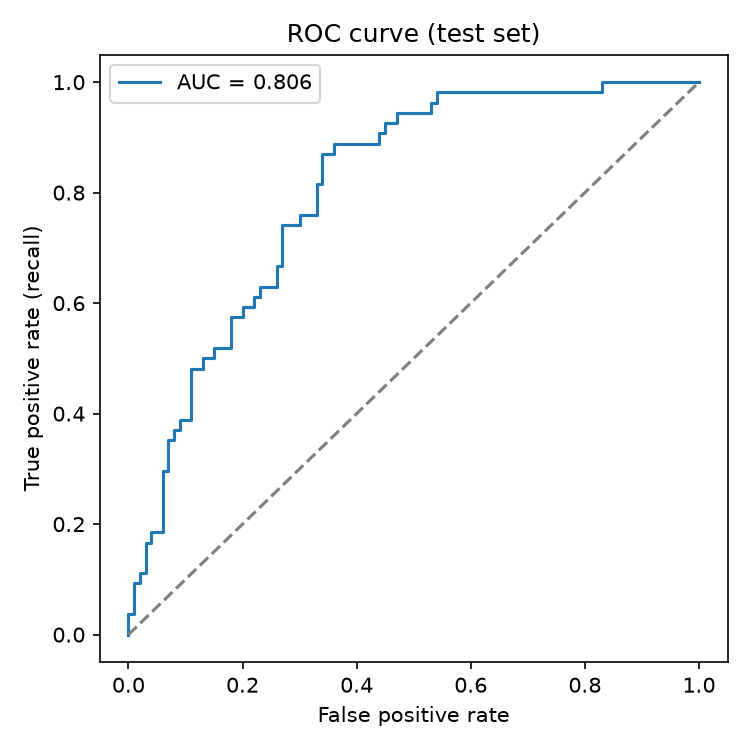

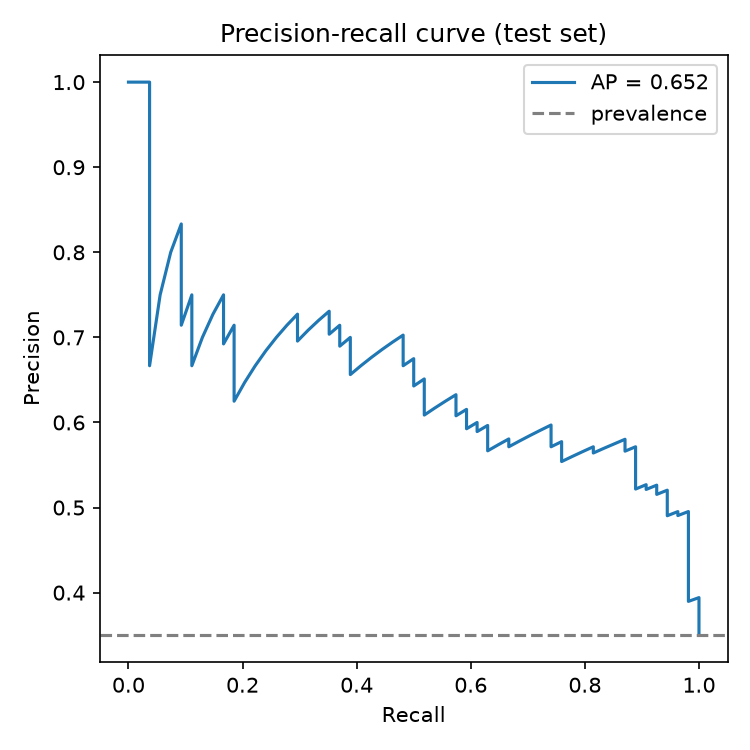

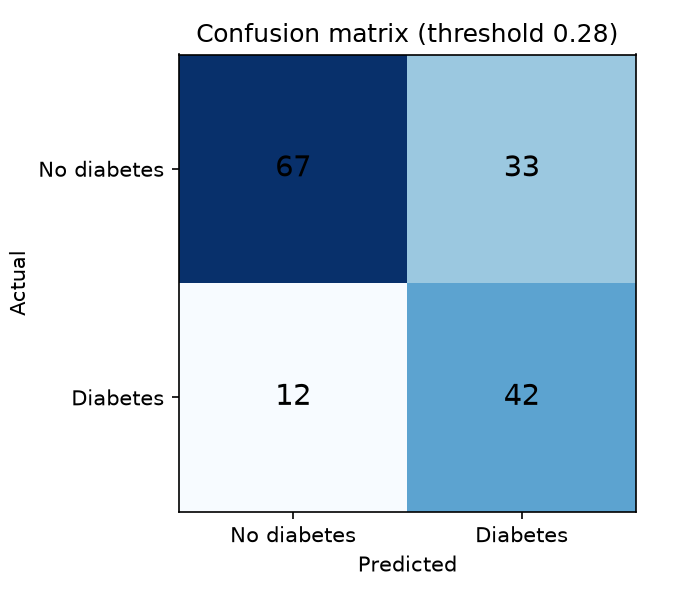

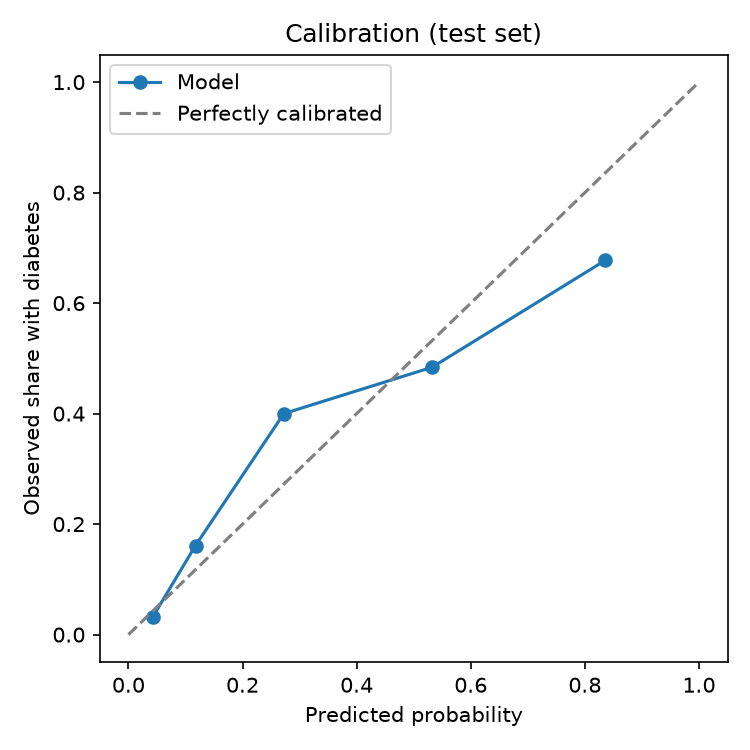

In [4]:
for name in ["roc_curve", "pr_curve", "confusion_matrix", "calibration_curve"]:
    display(Image(REPORTS / f"{name}.png", width=420))

**Things to say in the report**

- The test set has only 154 rows, so the confidence interval on AUC is wide. Report the interval, not just the point estimate.
- Accuracy alone is misleading (about 65% of patients are non-diabetic). Lead with recall and ROC-AUC.
- The threshold is below 0.5 on purpose: for screening, a missed diabetic costs more than a false alarm. The price is lower precision.

## 3. Who does the model miss? (false negatives on the test set)

In [5]:
pred = (proba >= thr).astype(int)
errors = X_test.assign(actual=y_test.values, probability=proba.round(3), predicted=pred)
fn = errors[(errors.actual == 1) & (errors.predicted == 0)].sort_values("probability")
print(f"{len(fn)} diabetic patients scored below the threshold:")
fn

12 diabetic patients scored below the threshold:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,actual,probability,predicted
6,3,78,50,32,88,31.0,0.248,26,1,0.042,0
124,0,113,76,0,0,33.3,0.278,23,1,0.122,0
276,7,106,60,24,0,26.5,0.296,29,1,0.123,0
38,2,90,68,42,0,38.2,0.503,27,1,0.144,0
419,3,129,64,29,115,26.4,0.219,28,1,0.152,0
17,7,107,74,0,0,29.6,0.254,31,1,0.167,0
366,6,124,72,0,0,27.6,0.368,29,1,0.217,0
678,3,121,52,0,0,36.0,0.127,25,1,0.231,0
630,7,114,64,0,0,27.4,0.732,34,1,0.251,0
264,4,123,62,0,0,32.0,0.226,35,1,0.258,0


In [6]:
# Are the misses concentrated where the data was not measured (zeros = missing)?
for col in ["Insulin", "SkinThickness", "BloodPressure"]:
    print(f"{col:<14} zero in {(fn[col] == 0).mean():.0%} of false negatives vs {(X_test[col] == 0).mean():.0%} of all test rows")

Insulin        zero in 75% of false negatives vs 55% of all test rows
SkinThickness  zero in 58% of false negatives vs 34% of all test rows
BloodPressure  zero in 8% of false negatives vs 8% of all test rows


## 4. Next

1. Explainability: SHAP on `models/pipeline_uncalibrated.joblib` (the calibrated model is a thin sigmoid on top, so contributions come from the pipeline), and DiCE for counterfactuals.
2. FastAPI `POST /predict` that calls `predict_one()` from `ml/src/predict.py`.
3. Connect the dashboard to the API.